Loading Housing Dataset...

First Five Rows:
   MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0          60       RL         65.0     8450   Pave   NaN      Reg   
1          20       RL         80.0     9600   Pave   NaN      Reg   
2          60       RL         68.0    11250   Pave   NaN      IR1   
3          70       RL         60.0     9550   Pave   NaN      IR1   
4          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities LotConfig  ... PoolArea PoolQC Fence MiscFeature  \
0         Lvl    AllPub    Inside  ...        0    NaN   NaN         NaN   
1         Lvl    AllPub       FR2  ...        0    NaN   NaN         NaN   
2         Lvl    AllPub    Inside  ...        0    NaN   NaN         NaN   
3         Lvl    AllPub    Corner  ...        0    NaN   NaN         NaN   
4         Lvl    AllPub       FR2  ...        0    NaN   NaN         NaN   

  MiscVal MoSold  YrSold  SaleType  SaleCondition  SalePrice  
0       0     

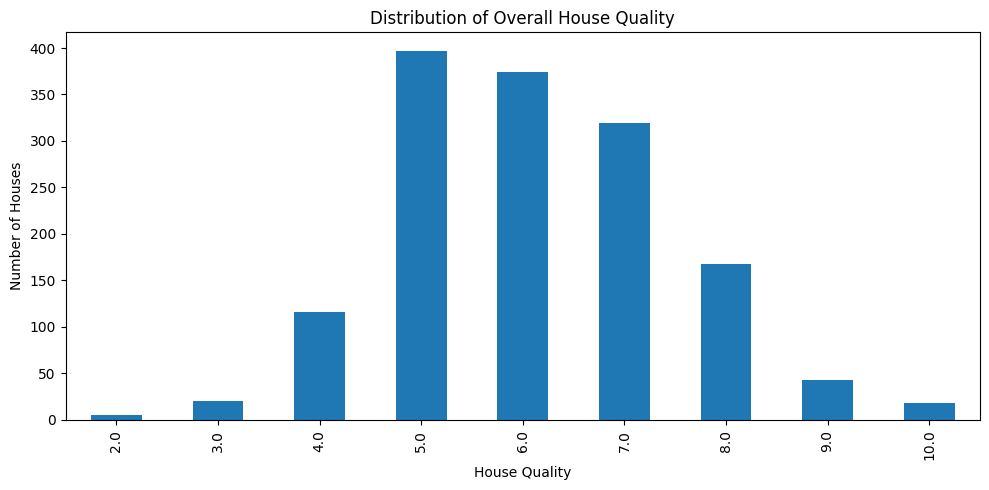

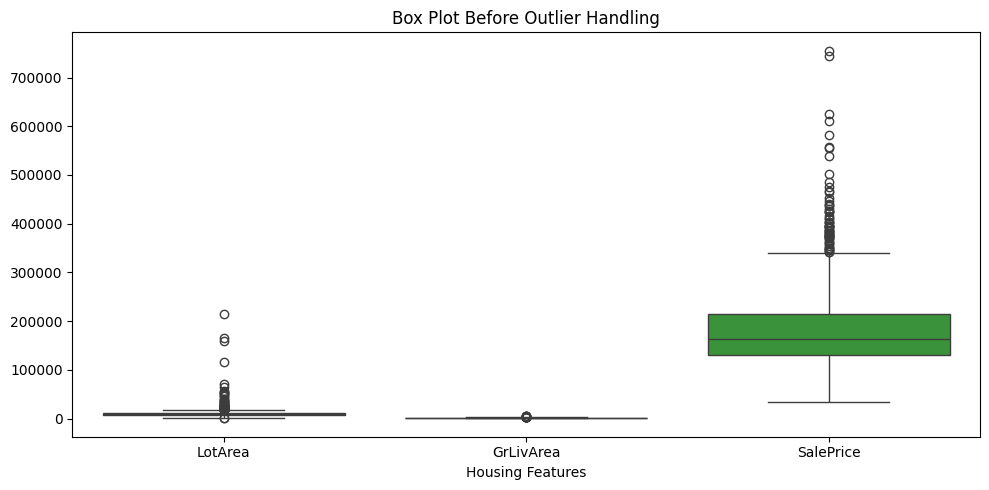

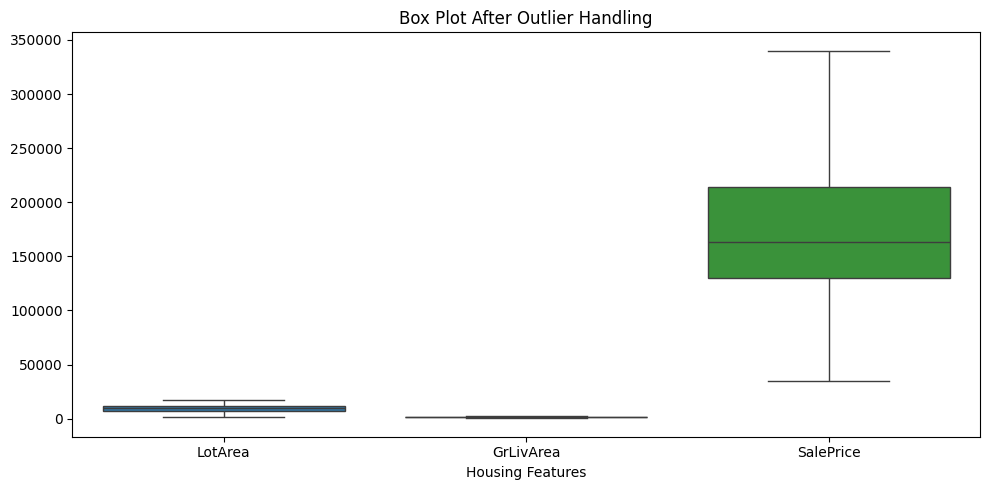

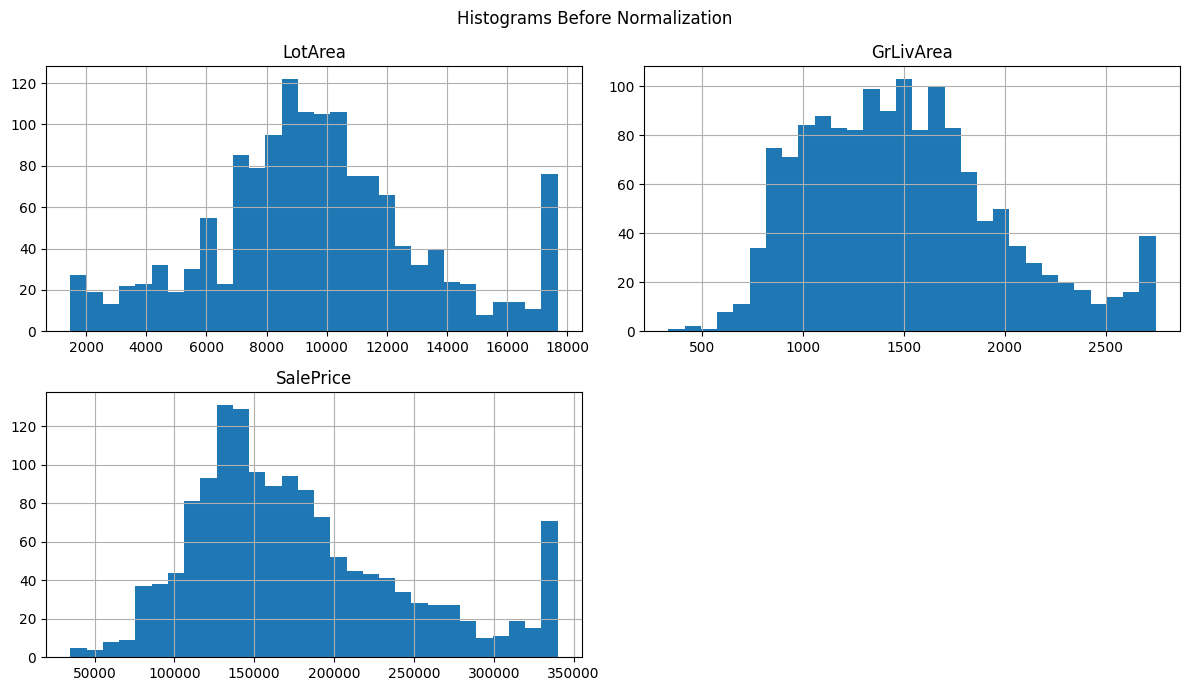

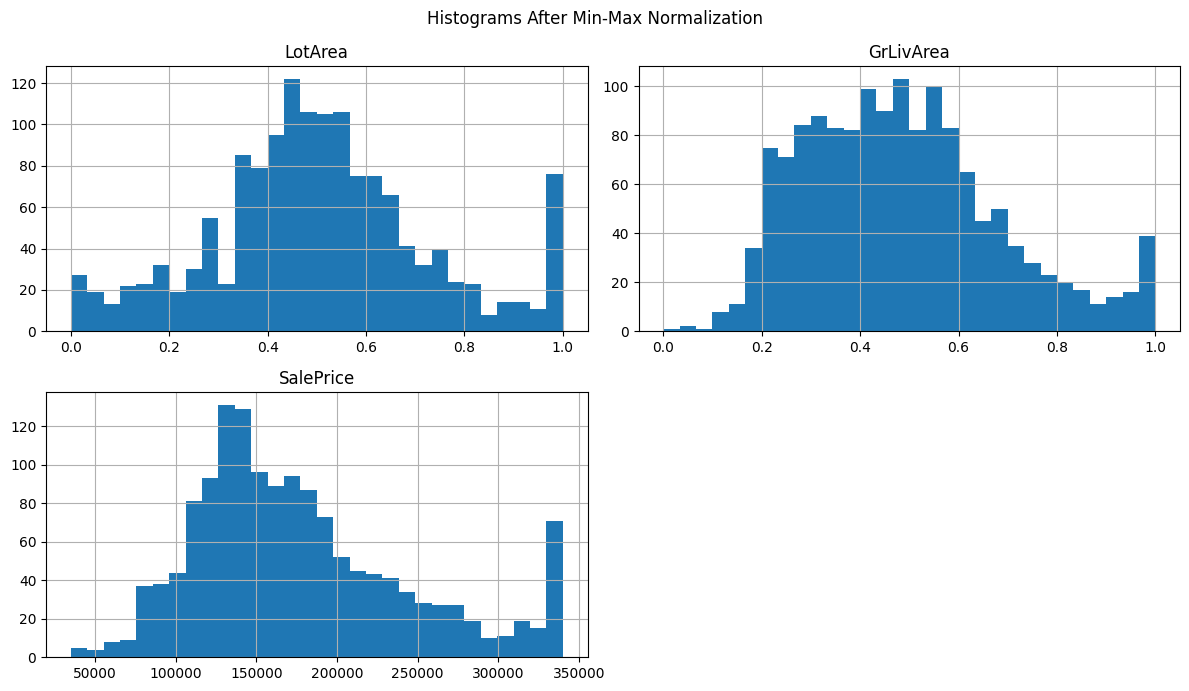

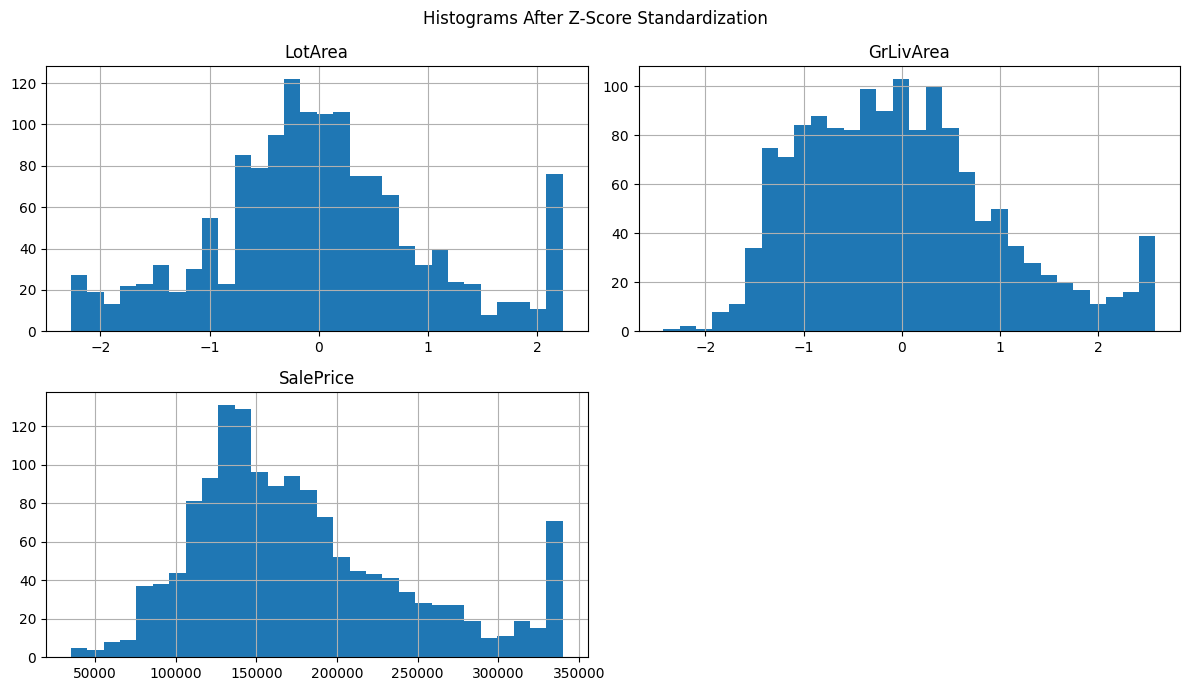

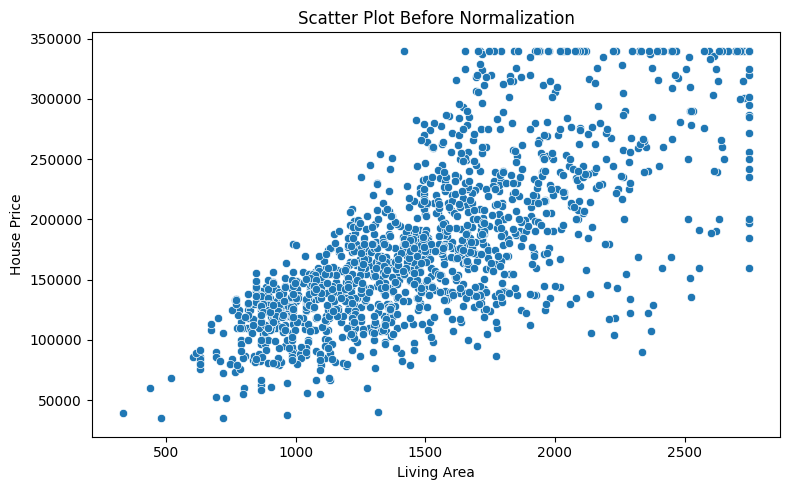

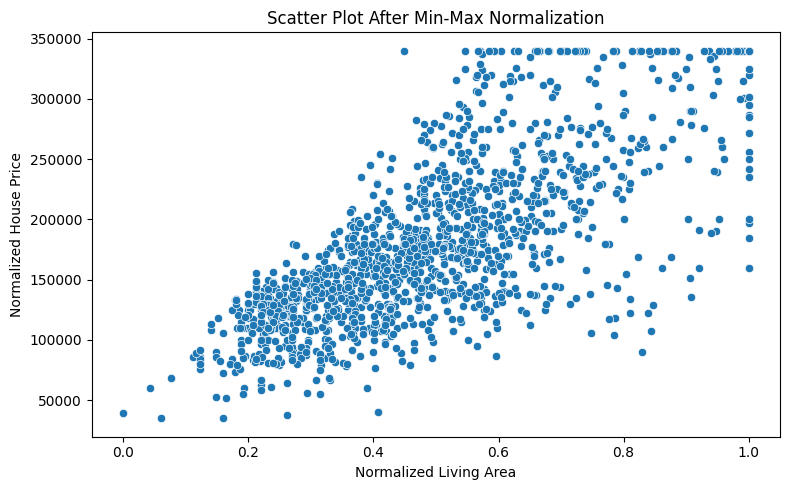

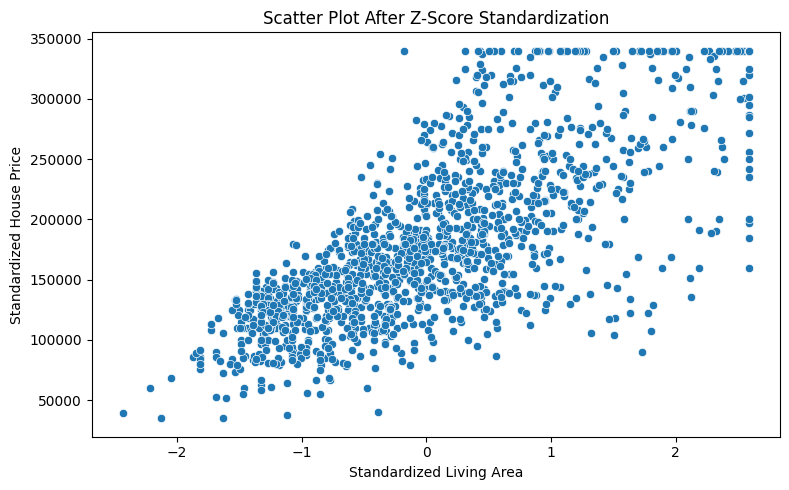


========== ORIGINAL DATA ==========
            LotArea    GrLivArea      SalePrice
count   1460.000000  1460.000000    1460.000000
mean    9647.388014  1503.735873  177331.526370
std     3594.356399   481.375641   67205.835915
min     1481.500000   334.000000   34900.000000
25%     7553.500000  1129.500000  129975.000000
50%     9478.500000  1464.000000  163000.000000
75%    11601.500000  1776.750000  214000.000000
max    17673.500000  2747.625000  340037.500000

========== MIN-MAX NORMALIZED DATA ==========
           LotArea    GrLivArea      SalePrice
count  1460.000000  1460.000000    1460.000000
mean      0.504316     0.484639  177331.526370
std       0.221983     0.199441   67205.835915
min       0.000000     0.000000   34900.000000
25%       0.375000     0.329587  129975.000000
50%       0.493886     0.468175  163000.000000
75%       0.625000     0.597752  214000.000000
max       1.000000     1.000000  340037.500000

========== Z-SCORE STANDARDIZED DATA ==========
            

In [1]:

# ============================================================
# HOUSING DATASET PREPROCESSING AND DATA VISUALIZATION
# ============================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# ============================================================
# 2. LOAD HOUSING DATASET
# ============================================================

print("Loading Housing Dataset...")

housing = fetch_openml(
    name="house_prices",
    as_frame=True,
    parser="auto"
)

df = housing.data.copy()

# Add target variable
df["SalePrice"] = pd.to_numeric(
    housing.target, errors="coerce"
)

# Remove unnecessary ID column
df = df.drop(columns=["Id"], errors="ignore")

print("\nFirst Five Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

# ============================================================
# 3. IDENTIFY VARIABLE TYPES
# ============================================================

# Continuous numerical variables
continuous_cols = [
    col for col in df.select_dtypes(include=np.number).columns
    if df[col].nunique() > 20
]

# Discrete numerical variables
discrete_cols = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in continuous_cols
]

# Ordinal categorical variables
ordinal_cols = [
    "OverallQual", "OverallCond",
    "ExterQual", "ExterCond",
    "BsmtQual", "BsmtCond",
    "HeatingQC", "KitchenQual",
    "FireplaceQu", "GarageQual",
    "GarageCond", "PoolQC"
]

ordinal_cols = [
    col for col in ordinal_cols if col in df.columns
]

# Nominal categorical variables
categorical_cols = df.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

nominal_cols = [
    col for col in categorical_cols
    if col not in ordinal_cols
]

print("\nContinuous Variables:")
print(continuous_cols)

print("\nDiscrete Variables:")
print(discrete_cols)

print("\nOrdinal Variables:")
print(ordinal_cols)

print("\nNominal Variables:")
print(nominal_cols)

# ============================================================
# 4. REMOVE DUPLICATES
# ============================================================

print("\nDuplicate Rows Before Cleaning:",
      df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicate Rows After Cleaning:",
      df.duplicated().sum())

# ============================================================
# 5. HANDLE MISSING VALUES
# ============================================================

numeric_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = df.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Numerical missing values: Median
num_imputer = SimpleImputer(strategy="median")

df[numeric_cols] = num_imputer.fit_transform(
    df[numeric_cols]
)

# Categorical missing values: Mode
cat_imputer = SimpleImputer(strategy="most_frequent")

df[categorical_cols] = cat_imputer.fit_transform(
    df[categorical_cols]
)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum().sum())

# ============================================================
# 6. SAVE DATA BEFORE OUTLIER HANDLING
# ============================================================

original_df = df.copy()

# ============================================================
# 7. HANDLE OUTLIERS USING IQR METHOD
# ============================================================

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df[col] = df[col].clip(
        lower_limit,
        upper_limit
    )

print("\nOutliers Handled Using IQR Method.")

# ============================================================
# 8. ORDINAL ENCODING
# ============================================================

ordinal_mapping = {
    "Ex": 5,
    "Gd": 4,
    "TA": 3,
    "Fa": 2,
    "Po": 1,
    "None": 0
}

for col in ordinal_cols:

    if col in df.columns and col in categorical_cols:

        df[col] = df[col].map(
            ordinal_mapping
        ).fillna(0)

# ============================================================
# 9. NOMINAL ENCODING
# ============================================================

nominal_cols = [
    col for col in categorical_cols
    if col not in ordinal_cols
]

df = pd.get_dummies(
    df,
    columns=nominal_cols,
    drop_first=True,
    dtype=int
)

print("\nDataset After Encoding:")
print(df.head())

print("\nNew Dataset Shape:")
print(df.shape)

# ============================================================
# 10. MIN-MAX NORMALIZATION
# ============================================================

target = "SalePrice"

feature_cols = [
    col for col in df.select_dtypes(include=np.number).columns
    if col != target
]

minmax_scaler = MinMaxScaler()

minmax_data = df.copy()

minmax_data[feature_cols] = minmax_scaler.fit_transform(
    df[feature_cols]
)

print("\nMin-Max Normalized Data:")
print(minmax_data.head())

# ============================================================
# 11. Z-SCORE STANDARDIZATION
# ============================================================

standard_scaler = StandardScaler()

standard_data = df.copy()

standard_data[feature_cols] = standard_scaler.fit_transform(
    df[feature_cols]
)

print("\nZ-Score Standardized Data:")
print(standard_data.head())

# ============================================================
# 12. BAR PLOT
# ============================================================

plt.figure(figsize=(10, 5))

df["OverallQual"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Distribution of Overall House Quality")
plt.xlabel("House Quality")
plt.ylabel("Number of Houses")

plt.tight_layout()
plt.show()

# ============================================================
# 13. BOXPLOT BEFORE OUTLIER HANDLING
# ============================================================

box_cols = [
    "LotArea",
    "GrLivArea",
    "SalePrice"
]

plt.figure(figsize=(10, 5))

sns.boxplot(data=original_df[box_cols])

plt.title("Box Plot Before Outlier Handling")
plt.xlabel("Housing Features")

plt.tight_layout()
plt.show()

# ============================================================
# 14. BOXPLOT AFTER OUTLIER HANDLING
# ============================================================

plt.figure(figsize=(10, 5))

sns.boxplot(data=df[box_cols])

plt.title("Box Plot After Outlier Handling")
plt.xlabel("Housing Features")

plt.tight_layout()
plt.show()

# ============================================================
# 15. HISTOGRAM BEFORE NORMALIZATION
# ============================================================

hist_cols = [
    "LotArea",
    "GrLivArea",
    "SalePrice"
]

df[hist_cols].hist(
    figsize=(12, 7),
    bins=30
)

plt.suptitle("Histograms Before Normalization")

plt.tight_layout()
plt.show()

# ============================================================
# 16. HISTOGRAM AFTER MIN-MAX NORMALIZATION
# ============================================================

minmax_data[hist_cols].hist(
    figsize=(12, 7),
    bins=30
)

plt.suptitle("Histograms After Min-Max Normalization")

plt.tight_layout()
plt.show()

# ============================================================
# 17. HISTOGRAM AFTER Z-SCORE STANDARDIZATION
# ============================================================

standard_data[hist_cols].hist(
    figsize=(12, 7),
    bins=30
)

plt.suptitle("Histograms After Z-Score Standardization")

plt.tight_layout()
plt.show()

# ============================================================
# 18. SCATTER PLOT BEFORE NORMALIZATION
# ============================================================

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice"
)

plt.title("Scatter Plot Before Normalization")
plt.xlabel("Living Area")
plt.ylabel("House Price")

plt.tight_layout()
plt.show()

# ============================================================
# 19. SCATTER PLOT AFTER MIN-MAX NORMALIZATION
# ============================================================

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=minmax_data["GrLivArea"],
    y=minmax_data["SalePrice"]
)

plt.title("Scatter Plot After Min-Max Normalization")
plt.xlabel("Normalized Living Area")
plt.ylabel("Normalized House Price")

plt.tight_layout()
plt.show()

# ============================================================
# 20. SCATTER PLOT AFTER Z-SCORE STANDARDIZATION
# ============================================================

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=standard_data["GrLivArea"],
    y=standard_data["SalePrice"]
)

plt.title("Scatter Plot After Z-Score Standardization")
plt.xlabel("Standardized Living Area")
plt.ylabel("Standardized House Price")

plt.tight_layout()
plt.show()

# ============================================================
# 21. COMPARE DATA DISTRIBUTION
# ============================================================

print("\n========== ORIGINAL DATA ==========")

print(df[hist_cols].describe())

print("\n========== MIN-MAX NORMALIZED DATA ==========")

print(minmax_data[hist_cols].describe())

print("\n========== Z-SCORE STANDARDIZED DATA ==========")

print(standard_data[hist_cols].describe())

# ============================================================
# 22. SAVE PREPROCESSED DATASETS
# ============================================================

df.to_csv("housing_cleaned.csv", index=False)

minmax_data.to_csv(
    "housing_minmax_normalized.csv",
    index=False
)

standard_data.to_csv(
    "housing_zscore_standardized.csv",
    index=False
)

print("\nAll datasets saved successfully!")

print("\nHOUSING DATA PREPROCESSING COMPLETED!")